In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import mean_pinball_loss

In [2]:
df = pd.read_csv("../data/processed/dataset.csv",
                 sep=";", index_col=0, parse_dates=True)

print(df.shape)
print("First Date :", df.index.min().date())
print("Last Date :", df.index.max().date())
df.head()

(6702, 10)
First Date : 2000-03-29
Last Date : 2026-11-19


,r,r_lag1,abs_r,vol_5,vol_20,vol_60,range,VIX,VIX_range,target
Date,,,,,,,,,,
2000-03-29,0.000524,-0.010641,0.000524,0.010306,0.017494,0.015679,0.015910,24.100000,0.051037,-0.013750
2000-03-30,-0.013750,0.000524,0.013750,0.006545,0.017959,0.014914,0.028731,25.469999,0.081665,0.007139
2000-03-31,0.007139,-0.013750,0.007139,0.008459,0.017588,0.014934,0.023642,24.110001,0.063459,0.004919
2000-04-03,0.004919,0.007139,0.004919,0.009352,0.017190,0.014943,0.013433,24.030001,0.076155,-0.007492
2000-04-04,-0.007492,0.004919,0.007492,0.008741,0.015948,0.014600,0.073619,27.120001,0.291667,-0.004936


We then split the data into three parts. Each group of data has its own role. 
The training set is used to fit the model's parameters, the coefficients that the model computes itself from the data. 
The validation set is used to choose what the model does not choose: the hyperparameters, the features, or the model itself. We compare the possible configurations on this set. These steps cannot be carried out on the training set, because the most complex model would always win by learning the noise by heart. 
The test set gives an estimate of performance on data that has never been seen. This part of the data is used only once, at the very end. 
If we chose the best configuration by looking at the test set, the final score would no longer be a performance on unknown data. We use the validation set as the data we use to choose the hyperparameters, and we do not touch the test set at this stage.

For the data split, we chose a chronological split and not a random one. Our data are a time series. A random split would put days from 2020 or 2021 in the training set and earlier data in the test set, which is not possible, because it would mean that the model learns from future data. The scores would be good because of data leakage, and they would make no sense, since in a real situation we do not have access to the future. Moreover, in our VaR case, the risk model is used in real time every morning, using only past information. A random split would give a situation that does not exist.

As explained above, the data are a time series, so we do not split by proportion but by date. In our situation, this date determines which market regimes and past situations will be observable for the train, the validation and the test. If we used a classic 80/20 split on our data, the test would start in July 2021 and the COVID crash would be in the training set. However, the objective of our project is also to look at the model's reaction to volatility shocks, so our test must contain at least one major shock. By taking 2020 as the cut-off, it contains two: COVID and the 2022 rate shock. With this split we obtain 1,731 test days, which is above the 250 days required for regulatory backtesting that we mentioned in Step_2.md.

For the split between training and validation within the 2000-2020 data, we noticed that using the 2016-2019 period for validation is not optimal, because it does not contain any major crisis. If we tune hyperparameters on it and then evaluate on a stress period, we guarantee nothing. We therefore chose to keep a single set, which we call development, from 2000 to 2019, within which we will apply in the next notebook a TimeSeriesSplit that will create training/validation pairs. The test set remains untouched until the final evaluation.

In [3]:
dev  = df.loc[:"2019"]
test = df.loc["2020":]
print("Number of values in Development :" ,len(dev))
print("Number of values in Test :" ,len(test))

Number of values in Development : 4971
Number of values in Test : 1731


For the baseline algorithm we selected, it is historical simulation over 250 days. The VaR for day t is the empirical 1% quantile of the last 250 observed returns, which corresponds to the 2nd-3rd worst day of the past year. The one-day lag must not be overlooked, because the VaR announced on the morning of day t only uses the information available up to the close of day t−1, which is the real situation for a risk manager.

We chose this baseline for several reasons. This algorithm is the method used by banks. It is the point of comparison in the literature that we are seeking to analyse. It is the model we chose to work on from our problem statement onwards. And finally, it assumes no distributional form. Indeed, in the previous sections our EDA shows a kurtosis of 10.8 and an empirical 1% quantile at −3.46%, whereas it is −2.79% for a normal distribution. A Gaussian baseline, as the EDA shows, is disqualified. We use a 250-day window because it is the Basel regulatory minimum and it is also the more reactive of the two common options, which are 250 and 500 days. This choice makes the demonstration more robust: if the baseline adjusts slowly even with the more reactive of the two configurations, the limitation does not come from this parameter setting but from the method itself.

For the metrics, we use two. The pinball loss, which is the loss function specific to quantile regression. It applies an asymmetric penalty: at 1%, the cost of underestimating a loss is much higher than that of overestimating it. For this task, an RMSE would be unsuitable, because we are not predicting a mean but an extreme quantile. This is the loss that the models will have to minimise later on. The other metric is the violation rate, which is the proportion of days on which the realised loss exceeded the VaR. The expected result is 1%: above it, the model underestimates risk; below it, the model is too conservative and ties up capital unnecessarily.

We apply the split as explained above. The 250-day rolling window is computed on the full series, then restricted to the test period. If it were computed on the test set alone, the first 250 days would be lost because we would have no history, and with them the COVID crash, which is precisely what we are trying to observe. This does not correspond to data leakage, because we only look at past values.

In [4]:
var_hist = df["r"].rolling(250).quantile(0.01).shift(1)

var_test = var_hist.loc["2020":].dropna()
y_test   = test["target"].loc[var_test.index]

print(pd.DataFrame({"VaR": var_test, "Realised": y_test}).head())

pinball = mean_pinball_loss(y_test, var_test, alpha=0.01)
viol    = (y_test < var_test).mean()

print("Pinball loss   :", round(pinball, 6))
print("Violation rate :", round(100 * viol, 2), "%  (target: 1.00%)")
print("Violations     :", (y_test < var_test).sum(), "out for", len(y_test), "days")

                 VaR  Realised
Date                          
2020-01-02 -0.025376 -0.007085
2020-01-03 -0.025376  0.003527
2020-01-06 -0.025376 -0.002807
2020-01-07 -0.025376  0.004890
2020-01-08 -0.025376  0.006633
Pinball loss   : 0.000605
Violation rate : 1.96 %  (target: 1.00%)
Violations     : 34 out for 1731 days


In [5]:
periodes = {
    "Full test 2020-2026":   ("2020", "2026"),
    "Calm 2023-2026":        ("2023", "2026"),
    "Rate shock 2022":       ("2022", "2022"),
    "COVID Feb to Apr 2020": ("2020-02", "2020-04"),
    "March 2020":            ("2020-03", "2020-03"),
}

lignes = []
for nom, (a, b) in periodes.items():
    vt, yt = var_test.loc[a:b], y_test.loc[a:b]
    lignes.append({"Period": nom,
                   "Days": len(yt),
                   "Violations": int((yt < vt).sum()),
                   "Violation rate (%)": round(100 * (yt < vt).mean(), 2)})

resultats = pd.DataFrame(lignes).set_index("Period")
resultats

,Days,Violations,Violation rate (%)
Period,,,
Full test 2020-2026,1731,34,1.96
Calm 2023-2026,975,15,1.54
Rate shock 2022,251,10,3.98
COVID Feb to Apr 2020,62,8,12.90
March 2020,22,5,22.73


We notice that the overall violation rate of 1.96% hides two very different behaviours. In the calm period between 2023 and 2026, we are at 1.54%, close to the 1% target. But during COVID, from February to April 2020, we rise to 12.90%, and in March 2020 alone we reach 22.73%.

We also see that the higher the actual risk, the larger the model's error: 1.54% in the calm period, 3.98% during the 2022 rate shock, then 12.90% during COVID. This is the worst possible behaviour for a risk model, because it fails at the very moment when it is most needed.

In [6]:
retard = pd.DataFrame({
    "VaR (%)": (var_test.loc["2020-02-20":"2020-03-20"] * 100).round(2),
    "Realised (%)": (y_test.loc["2020-02-20":"2020-03-20"] * 100).round(2),
})
retard["Violation"] = retard["Realised (%)"] < retard["VaR (%)"]
retard

,VaR (%),Realised (%),Violation
Date,,,
2020-02-20,-2.54,-1.06,False
2020-02-21,-2.54,-3.41,True
2020-02-24,-2.54,-3.07,True
2020-02-25,-2.80,-0.38,False
2020-02-26,-3.00,-4.52,True
2020-02-27,-3.00,-0.83,False
2020-02-28,-3.05,4.50,False
2020-03-02,-3.05,-2.85,False
2020-03-03,-3.05,4.13,False


The second table explains the behavior of the model. The crash starts on 24 February 2020, and on that day the VaR still announces −2.54%. We have to wait until 17 March for it to reach −6.48%, which is almost three weeks. The assumption behind historical simulation, which says that tomorrow looks like the past year, is no longer true when the regime changes.

We can see that March 2020 contains only 22 days and 5 violations, so the 22.73% rate remains uncertain on such a small sample. The February to April period have 62 days and 8 violations, it gives the same result.

For the next step, the objective of the Machine Learning models is therefore not to improve the average pinball loss, but to reduce the gap between the calm period and the crisis period.

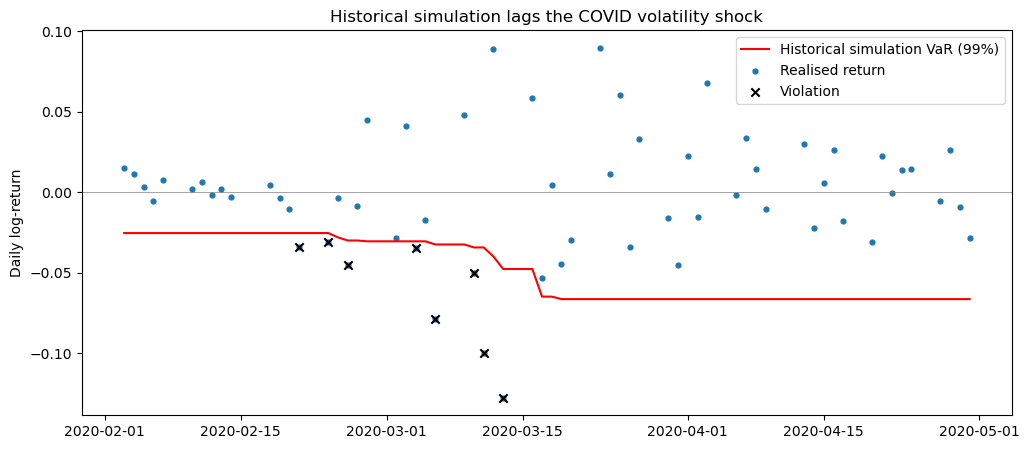

In [7]:
v = var_test.loc["2020-02":"2020-04"]
y = y_test.loc["2020-02":"2020-04"]

plt.figure(figsize=(12, 5))
plt.plot(v.index, v, color="red", label="Historical simulation VaR (99%)")
plt.scatter(y.index, y, s=12, label="Realised return")
plt.scatter(y.index[y < v], y[y < v], color="black", marker="x", label="Violation")
plt.axhline(0, color="grey", lw=0.5)
plt.title("Historical simulation lags the COVID volatility shock")
plt.ylabel("Daily log-return")
plt.legend()
plt.savefig("../results/figures/baseline_covid_2020.png", dpi=150, bbox_inches="tight")
plt.show()

This figure shows that the VaR stays almost flat while realised returns fall below it. The crosses mark the violations, we see a group of cross in early March, before the VaR has had time to adjust.

In [8]:
score = pd.DataFrame([{
    "model": "Historical simulation (250d)",
    "pinball_loss": pinball,
    "violation_rate": viol,
    "violations": int((y_test < var_test).sum()),
    "test_days": len(y_test),
}])

score.to_csv("../results/metrics/baseline.csv", sep=";", index=False)
score

,model,pinball_loss,violation_rate,violations,test_days
0,Historical simulation (250d),0.000605,0.019642,34,1731


In [9]:
resultats.to_csv("../results/metrics/baseline_by_period.csv", sep=";")

The baseline gives us a violation rate of 1.96% over the whole test set, which is almost twice the 1% target. But this value is an average: we go from 1.54% in the calm period to 22.73% during the shock in March 2020. We saw that the VaR takes almost three weeks to adjust to the shock, which confirms the slow reaction of historical simulation to regime changes. The pinball loss value of 0.000605 will serve as a reference for comparing the models in the next part, but the real criterion is to reduce the gap between the calm period and the crisis period.